In [61]:

# SECTION 1: IMPORTS AND MODEL CONFIGURATION

import pandas as pd
import numpy as np

from itertools import combinations

from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import (
    train_test_split,
    RandomizedSearchCV,
    StratifiedKFold,
    KFold
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from sklearn.utils.validation import check_is_fitted


RANDOM_STATE = 42

TEST_SIZE = 0.20

RETRAIN_BATCH_SIZE = 10



# Context inputs


LOCATIONS = [
    "Home",
    "Work",
    "Travel",
    "Social"
]

RELATIONSHIPS = [
    "Family",
    "Friend",
    "Acquaintance",
    "Colleague"
]

TIMES = [
    "Morning",
    "Afternoon",
    "Evening",
    "Night"
]

DAYS = [
    "Weekday",
    "Weekend"
]


CONTEXT_FEATURES = [
    "Location",
    "Relationship",
    "Time",
    "Day"
]



# Possible modalities


MODALITIES = [
    "Audio",
    "Visual",
    "Smell",
    "Taste",
    "Haptics"
]


# Required call-record columns

REQUIRED_COLUMNS = [
    "Location",
    "Relationship",
    "Time",
    "Day",
    "Duration_Minutes",
    "Timestamp",
    "Modalities"
]


print("Section 1 complete.")

Section 1 complete.


In [62]:

# SECTION 2: CREATE ALL VALID MODALITY COMBINATIONS

MODALITY_COMBINATIONS = []


for number_of_modalities in range(
    1,
    len(MODALITIES) + 1
):

    for combination in combinations(
        MODALITIES,
        number_of_modalities
    ):

        MODALITY_COMBINATIONS.append(
            combination
        )


VALID_COMBINATIONS = [

    " + ".join(
        combination
    )

    for combination
    in MODALITY_COMBINATIONS
]


print(
    "Number of valid modality combinations:",
    len(VALID_COMBINATIONS)
)


print("\nValid combinations:")

for combination in VALID_COMBINATIONS:

    print(
        combination
    )

Number of valid modality combinations: 31

Valid combinations:
Audio
Visual
Smell
Taste
Haptics
Audio + Visual
Audio + Smell
Audio + Taste
Audio + Haptics
Visual + Smell
Visual + Taste
Visual + Haptics
Smell + Taste
Smell + Haptics
Taste + Haptics
Audio + Visual + Smell
Audio + Visual + Taste
Audio + Visual + Haptics
Audio + Smell + Taste
Audio + Smell + Haptics
Audio + Taste + Haptics
Visual + Smell + Taste
Visual + Smell + Haptics
Visual + Taste + Haptics
Smell + Taste + Haptics
Audio + Visual + Smell + Taste
Audio + Visual + Smell + Haptics
Audio + Visual + Taste + Haptics
Audio + Smell + Taste + Haptics
Visual + Smell + Taste + Haptics
Audio + Visual + Smell + Taste + Haptics


In [63]:

# SECTION 3: DATA CLEANING AND VALIDATION


def canonicalize_modalities(
    modality_string
):

    if pd.isna(
        modality_string
    ):

        return np.nan


    selected = [

        item.strip().title()

        for item in
        str(
            modality_string
        ).split("+")
    ]


    # Remove duplicates

    selected = list(
        dict.fromkeys(
            selected
        )
    )


    # Reject invalid modality names

    if not all(

        modality
        in MODALITIES

        for modality
        in selected

    ):

        return np.nan


    # Put modalities in the standard order

    ordered = [

        modality

        for modality
        in MODALITIES

        if modality
        in selected
    ]


    if len(
        ordered
    ) == 0:

        return np.nan


    return " + ".join(
        ordered
    )



def clean_and_validate_data(
    data
):

    data = data.copy()

    # Check columns

    missing_columns = [

        column

        for column
        in REQUIRED_COLUMNS

        if column
        not in data.columns
    ]


    if missing_columns:

        raise ValueError(
            "Missing required columns: "
            +
            ", ".join(
                missing_columns
            )
        )


    data = data[
        REQUIRED_COLUMNS
    ].copy()

    # Clean context fields

    for column in CONTEXT_FEATURES:

        data[
            column
        ] = (

            data[
                column
            ]
            .astype(str)
            .str.strip()
            .str.title()
        )


    # Duration

    data[
        "Duration_Minutes"
    ] = pd.to_numeric(

        data[
            "Duration_Minutes"
        ],

        errors="coerce"
    )


    # --------------------------------------------------------
    # Timestamp
    # --------------------------------------------------------

    data[
        "Timestamp"
    ] = pd.to_datetime(

        data[
            "Timestamp"
        ],

        errors="coerce"
    )


    # --------------------------------------------------------
    # Modality combination
    # --------------------------------------------------------

    data[
        "Modalities"
    ] = (

        data[
            "Modalities"
        ]
        .apply(
            canonicalize_modalities
        )
    )


    rows_before = len(
        data
    )


    # --------------------------------------------------------
    # Remove missing/invalid data
    # --------------------------------------------------------

    data = (

        data
        .dropna(
            subset=REQUIRED_COLUMNS
        )
        .copy()
    )


    data = data[

        data[
            "Location"
        ].isin(
            LOCATIONS
        )

        &

        data[
            "Relationship"
        ].isin(
            RELATIONSHIPS
        )

        &

        data[
            "Time"
        ].isin(
            TIMES
        )

        &

        data[
            "Day"
        ].isin(
            DAYS
        )

        &

        data[
            "Modalities"
        ].isin(
            VALID_COMBINATIONS
        )

        &

        (
            data[
                "Duration_Minutes"
            ]
            > 0
        )
    ].copy()


    data = data.reset_index(
        drop=True
    )


    rows_removed = (

        rows_before

        -

        len(
            data
        )
    )


    print(
        f"Valid calls: "
        f"{len(data)}"
    )


    print(
        f"Invalid calls removed: "
        f"{rows_removed}"
    )


    return data


print(
    "Section 3 complete."
)

Section 3 complete.


In [64]:
# ============================================================
# SECTION 4: LOAD HISTORICAL DATASET
# ============================================================

HISTORICAL_FILE = input(
    "Enter the historical CSV filename, including .csv: "
).strip()


historical_data = pd.read_csv(
    HISTORICAL_FILE
)


print(
    f"\nRaw calls loaded: "
    f"{len(historical_data)}"
)


historical_data = clean_and_validate_data(
    historical_data
)


# Preserve original evaluation dataset

original_historical_data = (
    historical_data.copy()
)


ORIGINAL_DATASET_SIZE = len(
    historical_data
)


print(
    f"\nHistorical dataset ready: "
    f"{ORIGINAL_DATASET_SIZE} calls"
)

Enter the historical CSV filename, including .csv:  C:\Users\slaye\Downloads\Thesis Resources\mulsemedia_cumulative_1000_model_labels.csv



Raw calls loaded: 1000
Valid calls: 1000
Invalid calls removed: 0

Historical dataset ready: 1000 calls


In [65]:
# ============================================================
# SECTION 5:
# SHARED STRICT 80/20 TRAIN-TEST SPLIT
# ============================================================


import os
import hashlib
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split


RANDOM_STATE = 42

TRAIN_RATIO = 0.80
TEST_RATIO = 0.20


# ============================================================
# 1. PREPARE DATASET
# ============================================================

historical_data = (
    historical_data
    .reset_index(drop=True)
    .copy()
)


historical_data["_Row_ID"] = np.arange(
    len(historical_data)
)


total_calls = len(
    historical_data
)


# ============================================================
# 2. VERIFY THAT AN EXACT 80/20 SPLIT IS POSSIBLE
# ============================================================

if total_calls % 5 != 0:

    raise ValueError(

        f"The dataset contains {total_calls} calls. "

        "A mathematically exact 80/20 split requires the "
        "number of calls to be divisible by 5."
    )


training_calls_required = int(

    total_calls * 0.80
)


testing_calls_required = int(

    total_calls * 0.20
)


print("=" * 90)
print("SHARED STRICT 80/20 TRAIN-TEST SPLIT")
print("=" * 90)


print(
    f"Total historical calls: "
    f"{total_calls}"
)


print(
    f"Required training calls: "
    f"{training_calls_required}"
)


print(
    f"Required testing calls: "
    f"{testing_calls_required}"
)


# ============================================================
# 3. CREATE DATASET SIGNATURE


signature_columns = [

    column

    for column in REQUIRED_COLUMNS

    if column in historical_data.columns
]


signature_data = (

    historical_data[
        signature_columns
    ]
    .astype(str)
)


signature_hash_values = (

    pd.util
    .hash_pandas_object(
        signature_data,
        index=False
    )
    .values
    .tobytes()
)


dataset_signature = (

    hashlib
    .sha256(
        signature_hash_values
    )
    .hexdigest()
)


print(
    f"\nDataset signature: "
    f"{dataset_signature[:16]}..."
)


# ============================================================
# 4. SHARED SPLIT FILE


SHARED_SPLIT_FILE = (

    f"shared_split_"
    f"{total_calls}_calls.csv"
)


# ============================================================
# 5. LOAD EXISTING SHARED SPLIT IF AVAILABLE
# ============================================================

if os.path.exists(
    SHARED_SPLIT_FILE
):

    print(
        f"\nExisting shared split found:"
    )

    print(
        SHARED_SPLIT_FILE
    )


    split_table = pd.read_csv(
        SHARED_SPLIT_FILE
    )


    required_split_columns = [

        "_Row_ID",
        "Split",
        "Dataset_Signature"
    ]


    missing_split_columns = [

        column

        for column in required_split_columns

        if column not in split_table.columns
    ]


    if missing_split_columns:

        raise ValueError(

            "The existing shared split file is invalid. "
            "Missing columns: "

            +

            ", ".join(
                missing_split_columns
            )
        )


    # --------------------------------------------------------
    # Verify dataset signature
    # --------------------------------------------------------

    saved_signatures = (

        split_table[
            "Dataset_Signature"
        ]
        .dropna()
        .unique()
    )


    if (

        len(saved_signatures) != 1

        or

        saved_signatures[0]
        !=
        dataset_signature

    ):

        raise ValueError(

            "\nThe existing shared split file does not "
            "match the current historical dataset.\n\n"
            "Do not continue because SGD and Random Forest "
            "could then use different rows.\n\n"
            "If you intentionally changed the dataset, "
            "delete the old shared split file and rerun "
            "Section 5."
        )


    # --------------------------------------------------------
    # Extract row IDs
    # --------------------------------------------------------

    shared_train_indices = (

        split_table.loc[

            split_table[
                "Split"
            ]
            ==
            "Train",

            "_Row_ID"

        ]
        .astype(int)
        .tolist()
    )


    shared_test_indices = (

        split_table.loc[

            split_table[
                "Split"
            ]
            ==
            "Test",

            "_Row_ID"

        ]
        .astype(int)
        .tolist()
    )


    print(
        "\nExisting shared split loaded successfully."
    )


# ============================================================
# 6. CREATE NEW SHARED SPLIT
# ============================================================

else:

    print(
        "\nNo existing shared split was found."
    )

    print(
        "Creating a new shared split..."
    )




    class_counts = (

        historical_data[
            "Modalities"
        ]
        .value_counts()
    )


    singleton_classes = (

        class_counts[
            class_counts < 2
        ]
        .index
        .tolist()
    )


    if singleton_classes:

        print(
            "\nClasses with only one example:"
        )


        for class_name in singleton_classes:

            print(
                f"  - {class_name}"
            )


        print(
            "\nThese rows will remain in the shared "
            "training set without changing the 80/20 split."
        )


    else:

        print(
            "\nNo singleton classes detected."
        )


    # --------------------------------------------------------
    # Rows that must remain in training
    # --------------------------------------------------------

    forced_train_data = (

        historical_data[

            historical_data[
                "Modalities"
            ]
            .isin(
                singleton_classes
            )

        ]
        .copy()
    )


    # --------------------------------------------------------
    # Remaining rows available for normal splitting
    # --------------------------------------------------------

    splittable_data = (

        historical_data[

            ~historical_data[
                "Modalities"
            ]
            .isin(
                singleton_classes
            )

        ]
        .copy()
    )


    forced_train_count = len(
        forced_train_data
    )


    remaining_train_required = (

        training_calls_required

        -

        forced_train_count
    )


    if remaining_train_required < 0:

        raise ValueError(

            "There are more forced training rows than "
            "the allowed 80% training size."
        )


    # ========================================================
    # 7. DETERMINE WHETHER STRATIFICATION IS SAFE
    # ========================================================

    remaining_class_counts = (

        splittable_data[
            "Modalities"
        ]
        .value_counts()
    )


    number_of_remaining_classes = len(
        remaining_class_counts
    )


    if (

        len(
            remaining_class_counts
        ) > 0

        and

        remaining_class_counts.min() >= 2

        and

        testing_calls_required
        >=
        number_of_remaining_classes

        and

        remaining_train_required
        >=
        number_of_remaining_classes

    ):

        stratification_labels = (

            splittable_data[
                "Modalities"
            ]
        )


        print(
            "\nUsing stratification while preserving "
            "the strict 80/20 split."
        )


    else:

        stratification_labels = None


        print(
            "\nStrict 80/20 split will be created "
            "without stratification because the "
            "class distribution does not safely "
            "support stratification."
        )


    # ========================================================
    # 8. SPLIT THE DATA
    # ========================================================

    remaining_train_data, shared_test_data = (

        train_test_split(

            splittable_data,

            train_size=
                remaining_train_required,

            test_size=
                testing_calls_required,

            random_state=
                RANDOM_STATE,

            shuffle=True,

            stratify=
                stratification_labels
        )
    )


    # --------------------------------------------------------
    # Add singleton rows back into training
    # --------------------------------------------------------

    shared_train_data = pd.concat(

        [
            remaining_train_data,
            forced_train_data
        ],

        ignore_index=False
    )


    # --------------------------------------------------------
    # Sort by original row ID
    # --------------------------------------------------------

    shared_train_data = (

        shared_train_data
        .sort_values(
            "_Row_ID"
        )
        .reset_index(
            drop=True
        )
    )


    shared_test_data = (

        shared_test_data
        .sort_values(
            "_Row_ID"
        )
        .reset_index(
            drop=True
        )
    )


    # --------------------------------------------------------
    # Store row IDs
    # --------------------------------------------------------

    shared_train_indices = (

        shared_train_data[
            "_Row_ID"
        ]
        .astype(int)
        .tolist()
    )


    shared_test_indices = (

        shared_test_data[
            "_Row_ID"
        ]
        .astype(int)
        .tolist()
    )


    # ========================================================
    # 9. SAVE SHARED SPLIT
    # ========================================================

    train_id_set = set(
        shared_train_indices
    )


    test_id_set = set(
        shared_test_indices
    )


    split_table = pd.DataFrame({

        "_Row_ID":
            historical_data[
                "_Row_ID"
            ],

        "Split": [

            "Train"

            if row_id in train_id_set

            else "Test"

            for row_id
            in historical_data[
                "_Row_ID"
            ]

        ],

        "Dataset_Signature":
            dataset_signature
    })


    split_table.to_csv(

        SHARED_SPLIT_FILE,

        index=False
    )


    print(
        f"\nShared split saved as:"
    )


    print(
        SHARED_SPLIT_FILE
    )


# ============================================================
# 10. RECONSTRUCT SHARED TRAIN AND TEST DATA
# ============================================================

shared_train_data = (

    historical_data[

        historical_data[
            "_Row_ID"
        ]
        .isin(
            shared_train_indices
        )

    ]
    .sort_values(
        "_Row_ID"
    )
    .reset_index(
        drop=True
    )
)


shared_test_data = (

    historical_data[

        historical_data[
            "_Row_ID"
        ]
        .isin(
            shared_test_indices
        )

    ]
    .sort_values(
        "_Row_ID"
    )
    .reset_index(
        drop=True
    )
)


# ============================================================
# 11. STRICT VALIDATION CHECKS
# ============================================================

assert (
    len(
        shared_train_data
    )
    ==
    training_calls_required
), "Training set is not exactly 80%."


assert (
    len(
        shared_test_data
    )
    ==
    testing_calls_required
), "Test set is not exactly 20%."


assert (
    len(
        shared_train_data
    )
    +
    len(
        shared_test_data
    )
    ==
    total_calls
), "Train/test totals do not equal the full dataset."


assert (

    set(
        shared_train_indices
    )
    .isdisjoint(

        set(
            shared_test_indices
        )
    )

), "Training and testing rows overlap."


# ============================================================
# 12. ASSIGN STANDARD MODEL VARIABLES
# ============================================================

train_data = (
    shared_train_data.copy()
)


test_data = (
    shared_test_data.copy()
)


# ============================================================
# 13. TEST-SET SIGNATURE
# ============================================================

test_row_string = ",".join(

    map(
        str,
        shared_test_indices
    )
)


shared_test_signature = (

    hashlib
    .sha256(
        test_row_string.encode()
    )
    .hexdigest()
)


# ============================================================
# 14. FINAL SPLIT REPORT
# ============================================================

print("\n")
print("=" * 90)
print("SHARED SPLIT COMPLETE")
print("=" * 90)


print(
    f"Total calls: "
    f"{total_calls}"
)


print(
    f"Training calls: "
    f"{len(train_data)}"
)


print(
    f"Testing calls: "
    f"{len(test_data)}"
)


print(
    f"Training percentage: "
    f"{len(train_data) / total_calls * 100:.2f}%"
)


print(
    f"Testing percentage: "
    f"{len(test_data) / total_calls * 100:.2f}%"
)


print(
    f"\nShared test-set signature:"
)


print(
    shared_test_signature
)


print(
    "\nIMPORTANT:"
)


print(
    "SGD and Random Forest must have the SAME "
    "test-set signature for this dataset."
)


print("=" * 90)

SHARED STRICT 80/20 TRAIN-TEST SPLIT
Total historical calls: 1000
Required training calls: 800
Required testing calls: 200

Dataset signature: 1ac4ee4dc62d46b7...

Existing shared split found:
shared_split_1000_calls.csv

Existing shared split loaded successfully.


SHARED SPLIT COMPLETE
Total calls: 1000
Training calls: 800
Testing calls: 200
Training percentage: 80.00%
Testing percentage: 20.00%

Shared test-set signature:
49f1b213d6b151ab7c45785fba16e5ec1aab33d1da71d69a024de84118aae531

IMPORTANT:
SGD and Random Forest must have the SAME test-set signature for this dataset.


In [66]:
# ============================================================
# SECTION 6:
# RANDOM FOREST HYPERPARAMETER TUNING
# ============================================================

from sklearn.preprocessing import OneHotEncoder

from sklearn.ensemble import (
    RandomForestClassifier
)

from sklearn.pipeline import Pipeline

from sklearn.model_selection import (
    RandomizedSearchCV,
    StratifiedKFold,
    KFold
)


# ============================================================
# 1. VERIFY SECTION 5 HAS BEEN RUN
# ============================================================

required_section_5_variables = [

    "train_data",
    "test_data",
    "shared_train_indices",
    "shared_test_indices"
]


missing_variables = [

    variable

    for variable
    in required_section_5_variables

    if variable not in globals()
]


if missing_variables:

    raise RuntimeError(

        "Section 5 has not been run correctly.\n\n"
        "Missing variables: "

        +

        ", ".join(
            missing_variables
        )

        +

        "\n\nRun Section 5 before Section 6."
    )


print("=" * 90)
print("RANDOM FOREST HYPERPARAMETER TUNING")
print("=" * 90)


print(
    f"Shared training calls: "
    f"{len(train_data)}"
)


print(
    f"Shared held-out test calls: "
    f"{len(test_data)}"
)


print(
    "\nThe held-out test set will NOT be used "
    "during hyperparameter tuning."
)


# ============================================================
# 2. PREPARE TRAINING INPUTS
# ============================================================

X_tuning = (

    train_data[
        CONTEXT_FEATURES
    ]
    .copy()
)


y_tuning = (

    train_data[
        "Modalities"
    ]
    .copy()
)


# ============================================================
# 3. ONE-HOT ENCODER
# ============================================================

tuning_encoder = OneHotEncoder(

    categories=[
        LOCATIONS,
        RELATIONSHIPS,
        TIMES,
        DAYS
    ],

    handle_unknown="ignore",

    sparse_output=False
)


# ============================================================
# 4. BASE RANDOM FOREST
# ============================================================

tuning_rf = RandomForestClassifier(

    random_state=
        RANDOM_STATE,

    n_jobs=-1
)


# ============================================================
# 5. PIPELINE
# ============================================================

tuning_pipeline = Pipeline([

    (
        "encoder",
        tuning_encoder
    ),

    (
        "rf",
        tuning_rf
    )

])


# ============================================================
# 6. HYPERPARAMETER SEARCH SPACE
# ============================================================

parameter_distribution = {

    "rf__n_estimators": [

        150,
        200,
        300,
        400,
        500
    ],

    "rf__max_depth": [

        None,
        4,
        6,
        8,
        10,
        12,
        15,
        20
    ],

    "rf__min_samples_split": [

        2,
        4,
        5,
        8,
        10,
        15
    ],

    "rf__min_samples_leaf": [

        1,
        2,
        3,
        4,
        5,
        8
    ],

    "rf__max_features": [

        "sqrt",
        "log2",
        None
    ],

    "rf__class_weight": [

        None,
        "balanced",
        "balanced_subsample"
    ],

    "rf__criterion": [

        "gini",
        "entropy"
    ]
}


# ============================================================
# 7. SELECT SAFE CROSS-VALIDATION STRATEGY
# ============================================================

class_counts = (

    y_tuning
    .value_counts()
)


minimum_class_count = int(

    class_counts.min()
)


number_of_training_classes = len(
    class_counts
)


print(
    f"\nNumber of modality classes "
    f"in training data: "
    f"{number_of_training_classes}"
)


print(
    f"Smallest training class: "
    f"{minimum_class_count} call(s)"
)


# ------------------------------------------------------------
# Use stratified cross-validation whenever possible.
# ------------------------------------------------------------

if minimum_class_count >= 2:

    number_of_folds = min(

        5,

        minimum_class_count
    )


    cv_strategy = StratifiedKFold(

        n_splits=
            number_of_folds,

        shuffle=True,

        random_state=
            RANDOM_STATE
    )


    print(
        f"\nCross-validation strategy: "
        f"StratifiedKFold"
    )


    print(
        f"Cross-validation folds: "
        f"{number_of_folds}"
    )


else:

    # --------------------------------------------------------
    # If one training class contains only one record,
    # stratification cannot be safely performed.
    # --------------------------------------------------------

    number_of_folds = min(

        5,

        len(
            train_data
        )
    )


    if number_of_folds < 2:

        raise ValueError(

            "The training dataset is too small "
            "for cross-validation."
        )


    cv_strategy = KFold(

        n_splits=
            number_of_folds,

        shuffle=True,

        random_state=
            RANDOM_STATE
    )


    print(
        f"\nCross-validation strategy: "
        f"KFold"
    )


    print(
        f"Cross-validation folds: "
        f"{number_of_folds}"
    )


# ============================================================
# 8. RANDOMISED HYPERPARAMETER SEARCH
# ============================================================

random_search = RandomizedSearchCV(

    estimator=
        tuning_pipeline,

    param_distributions=
        parameter_distribution,

    n_iter=50,

    scoring={

        "accuracy":
            "accuracy",

        "macro_precision":
            "precision_macro",

        "macro_recall":
            "recall_macro",

        "macro_f1":
            "f1_macro",

        "weighted_precision":
            "precision_weighted",

        "weighted_recall":
            "recall_weighted",

        "weighted_f1":
            "f1_weighted"
    },

    # Accuracy remains the primary selection metric.
    refit="accuracy",

    cv=
        cv_strategy,

    random_state=
        RANDOM_STATE,

    n_jobs=-1,

    verbose=1,

    return_train_score=True,

    error_score=np.nan
)


# ============================================================
# 9. RUN HYPERPARAMETER SEARCH
# ============================================================

print("\n")
print(
    "Starting Random Forest hyperparameter tuning..."
)


random_search.fit(

    X_tuning,

    y_tuning
)


print(
    "\nHyperparameter tuning complete."
)


# ============================================================
# 10. EXTRACT BEST RANDOM FOREST PARAMETERS
# ============================================================

BEST_RF_PARAMS = {

    parameter.replace(
        "rf__",
        ""
    ):
        value

    for parameter, value
    in random_search.best_params_.items()

    if parameter.startswith(
        "rf__"
    )
}


# ============================================================
# 11. DISPLAY BEST PARAMETERS
# ============================================================

print("\n")
print("=" * 90)
print("BEST RANDOM FOREST PARAMETERS")
print("=" * 90)


for parameter, value in (

    BEST_RF_PARAMS.items()
):

    print(
        f"{parameter}: {value}"
    )


# ============================================================
# 12. BEST CROSS-VALIDATION RESULTS
# ============================================================

best_index = (

    random_search.best_index_
)


cv_results = (

    random_search.cv_results_
)


best_cv_accuracy = (

    cv_results[
        "mean_test_accuracy"
    ][
        best_index
    ]
)


best_cv_macro_precision = (

    cv_results[
        "mean_test_macro_precision"
    ][
        best_index
    ]
)


best_cv_macro_recall = (

    cv_results[
        "mean_test_macro_recall"
    ][
        best_index
    ]
)


best_cv_macro_f1 = (

    cv_results[
        "mean_test_macro_f1"
    ][
        best_index
    ]
)


best_cv_weighted_precision = (

    cv_results[
        "mean_test_weighted_precision"
    ][
        best_index
    ]
)


best_cv_weighted_recall = (

    cv_results[
        "mean_test_weighted_recall"
    ][
        best_index
    ]
)


best_cv_weighted_f1 = (

    cv_results[
        "mean_test_weighted_f1"
    ][
        best_index
    ]
)


# ============================================================
# 13. DISPLAY CROSS-VALIDATION PERFORMANCE
# ============================================================

print("\n")
print("=" * 90)
print("BEST CROSS-VALIDATION PERFORMANCE")
print("=" * 90)


print(
    f"Accuracy: "
    f"{best_cv_accuracy * 100:.2f}%"
)


print(
    f"Macro Precision: "
    f"{best_cv_macro_precision:.4f}"
)


print(
    f"Macro Recall: "
    f"{best_cv_macro_recall:.4f}"
)


print(
    f"Macro F1: "
    f"{best_cv_macro_f1:.4f}"
)


print(
    f"Weighted Precision: "
    f"{best_cv_weighted_precision:.4f}"
)


print(
    f"Weighted Recall: "
    f"{best_cv_weighted_recall:.4f}"
)


print(
    f"Weighted F1: "
    f"{best_cv_weighted_f1:.4f}"
)


# ============================================================
# 14. SUMMARY TABLE
# ============================================================

tuning_results_summary = pd.DataFrame({

    "Metric": [

        "Training calls used for tuning",

        "Held-out test calls excluded from tuning",

        "Cross-validation folds",

        "CV Accuracy",

        "CV Macro Precision",

        "CV Macro Recall",

        "CV Macro F1",

        "CV Weighted Precision",

        "CV Weighted Recall",

        "CV Weighted F1"
    ],

    "Result": [

        len(
            train_data
        ),

        len(
            test_data
        ),

        number_of_folds,

        round(
            best_cv_accuracy,
            4
        ),

        round(
            best_cv_macro_precision,
            4
        ),

        round(
            best_cv_macro_recall,
            4
        ),

        round(
            best_cv_macro_f1,
            4
        ),

        round(
            best_cv_weighted_precision,
            4
        ),

        round(
            best_cv_weighted_recall,
            4
        ),

        round(
            best_cv_weighted_f1,
            4
        )
    ]
})


print("\n")
display(
    tuning_results_summary
)


print("\n")
print("=" * 90)
print("SECTION 6 COMPLETE")
print("=" * 90)


print(
    "\nThe held-out 20% test set remains untouched."
)


print(
    "The selected hyperparameters can now be used "
    "to train the final Random Forest in Section 7."
)

RANDOM FOREST HYPERPARAMETER TUNING
Shared training calls: 800
Shared held-out test calls: 200

The held-out test set will NOT be used during hyperparameter tuning.

Number of modality classes in training data: 8
Smallest training class: 4 call(s)

Cross-validation strategy: StratifiedKFold
Cross-validation folds: 4


Starting Random Forest hyperparameter tuning...
Fitting 4 folds for each of 50 candidates, totalling 200 fits

Hyperparameter tuning complete.


BEST RANDOM FOREST PARAMETERS
n_estimators: 200
min_samples_split: 4
min_samples_leaf: 4
max_features: None
max_depth: 8
criterion: entropy
class_weight: None


BEST CROSS-VALIDATION PERFORMANCE
Accuracy: 84.88%
Macro Precision: 0.7299
Macro Recall: 0.7211
Macro F1: 0.7220
Weighted Precision: 0.8447
Weighted Recall: 0.8488
Weighted F1: 0.8440




,Metric,Result
0,Training calls used for tuning,800.0000
1,Held-out test calls excluded from tuning,200.0000
2,Cross-validation folds,4.0000
3,CV Accuracy,0.8488
4,CV Macro Precision,0.7299
5,CV Macro Recall,0.7211
6,CV Macro F1,0.7220
7,CV Weighted Precision,0.8447
8,CV Weighted Recall,0.8488
9,CV Weighted F1,0.8440




SECTION 6 COMPLETE

The held-out 20% test set remains untouched.
The selected hyperparameters can now be used to train the final Random Forest in Section 7.


In [67]:
# ============================================================
# SECTION 7: TRAIN FINAL RANDOM FOREST
# ============================================================

encoder = OneHotEncoder(

    categories=[
        LOCATIONS,
        RELATIONSHIPS,
        TIMES,
        DAYS
    ],

    handle_unknown="ignore",

    sparse_output=False
)


X_train_encoded = encoder.fit_transform(

    train_data[
        CONTEXT_FEATURES
    ]
)


X_test_encoded = encoder.transform(

    test_data[
        CONTEXT_FEATURES
    ]
)


y_train = (

    train_data[
        "Modalities"
    ]
)


y_test = (

    test_data[
        "Modalities"
    ]
)


model = RandomForestClassifier(

    **BEST_RF_PARAMS,

    random_state=RANDOM_STATE,

    n_jobs=-1
)


model.fit(

    X_train_encoded,

    y_train
)


print(
    "Final Random Forest trained successfully."
)


print(
    f"Training calls: "
    f"{len(train_data)}"
)


print(
    f"Encoded features: "
    f"{X_train_encoded.shape[1]}"
)


print(
    f"Learned modality classes: "
    f"{len(model.classes_)}"
)

Final Random Forest trained successfully.
Training calls: 800
Encoded features: 14
Learned modality classes: 8


In [68]:
# ============================================================
# SECTION 8: FINAL HELD-OUT TEST EVALUATION
# ============================================================

test_predictions = model.predict(
    X_test_encoded
)


test_probabilities = model.predict_proba(
    X_test_encoded
)


test_confidence = np.max(

    test_probabilities,

    axis=1
)


accuracy = accuracy_score(

    y_test,

    test_predictions
)


macro_precision = precision_score(

    y_test,

    test_predictions,

    average="macro",

    zero_division=0
)


macro_recall = recall_score(

    y_test,

    test_predictions,

    average="macro",

    zero_division=0
)


macro_f1 = f1_score(

    y_test,

    test_predictions,

    average="macro",

    zero_division=0
)


weighted_precision = precision_score(

    y_test,

    test_predictions,

    average="weighted",

    zero_division=0
)


weighted_recall = recall_score(

    y_test,

    test_predictions,

    average="weighted",

    zero_division=0
)


weighted_f1 = f1_score(

    y_test,

    test_predictions,

    average="weighted",

    zero_division=0
)


correct_predictions = int(

    np.sum(

        np.array(
            y_test
        )

        ==

        test_predictions
    )
)


incorrect_predictions = (

    len(
        test_data
    )

    -

    correct_predictions
)


average_confidence = (

    np.mean(
        test_confidence
    )

    *

    100
)


print("=" * 90)
print("FINAL RANDOM FOREST RESULTS")
print("=" * 90)


print(
    f"Historical calls: "
    f"{len(train_data) + len(test_data)}"
)


print(
    f"Training calls: "
    f"{len(train_data)}"
)


print(
    f"Testing calls: "
    f"{len(test_data)}"
)


print(
    f"\nAccuracy: "
    f"{accuracy * 100:.2f}%"
)


print(
    f"Correct predictions: "
    f"{correct_predictions}/"
    f"{len(test_data)}"
)


print(
    f"Incorrect predictions: "
    f"{incorrect_predictions}/"
    f"{len(test_data)}"
)


print(
    f"\nMacro Precision: "
    f"{macro_precision:.4f}"
)


print(
    f"Macro Recall: "
    f"{macro_recall:.4f}"
)


print(
    f"Macro F1: "
    f"{macro_f1:.4f}"
)


print(
    f"\nWeighted Precision: "
    f"{weighted_precision:.4f}"
)


print(
    f"Weighted Recall: "
    f"{weighted_recall:.4f}"
)


print(
    f"Weighted F1: "
    f"{weighted_f1:.4f}"
)


print(
    f"\nAverage confidence: "
    f"{average_confidence:.2f}%"
)

FINAL RANDOM FOREST RESULTS
Historical calls: 1000
Training calls: 800
Testing calls: 200

Accuracy: 87.00%
Correct predictions: 174/200
Incorrect predictions: 26/200

Macro Precision: 0.7691
Macro Recall: 0.7439
Macro F1: 0.7493

Weighted Precision: 0.8669
Weighted Recall: 0.8700
Weighted F1: 0.8643

Average confidence: 82.46%


In [69]:
# ============================================================
# SECTION 9: DETAILED CLASSIFICATION RESULTS
# ============================================================

print(
    classification_report(

        y_test,

        test_predictions,

        zero_division=0
    )
)


evaluation_results = (

    test_data[
        CONTEXT_FEATURES
        +
        [
            "Modalities"
        ]
    ]
    .copy()
    .reset_index(
        drop=True
    )
)


evaluation_results[
    "Predicted"
] = test_predictions


evaluation_results[
    "Correct"
] = (

    evaluation_results[
        "Modalities"
    ]

    ==

    evaluation_results[
        "Predicted"
    ]
)


evaluation_results[
    "Confidence_%"
] = (

    test_confidence

    *

    100
).round(2)


display(
    evaluation_results
)

                                          precision    recall  f1-score   support

                                   Audio       0.92      0.96      0.94        25
                         Audio + Haptics       0.90      0.92      0.91        38
                          Audio + Visual       0.86      0.94      0.90        70
                Audio + Visual + Haptics       0.87      0.68      0.76        40
        Audio + Visual + Smell + Haptics       0.82      1.00      0.90         9
Audio + Visual + Smell + Taste + Haptics       1.00      0.67      0.80         3
                                  Visual       0.00      0.00      0.00         1
                        Visual + Haptics       0.79      0.79      0.79        14

                                accuracy                           0.87       200
                               macro avg       0.77      0.74      0.75       200
                            weighted avg       0.87      0.87      0.86       200



,Location,Relationship,Time,Day,Modalities,Predicted,Correct,Confidence_%
0,Work,Family,Morning,Weekend,Audio,Audio,True,71.70
1,Travel,Acquaintance,Morning,Weekday,Visual,Audio + Haptics,False,70.37
2,Travel,Colleague,Night,Weekend,Audio + Haptics,Audio + Haptics,True,87.31
3,Travel,Friend,Morning,Weekend,Audio + Haptics,Audio + Haptics,True,90.29
4,Social,Friend,Evening,Weekday,Audio + Visual + Haptics,Audio + Visual + Haptics,True,87.31
...,...,...,...,...,...,...,...,...
195,Social,Acquaintance,Morning,Weekday,Audio + Visual,Audio + Visual,True,92.77
196,Work,Acquaintance,Night,Weekday,Audio + Visual,Audio + Visual,True,78.65
197,Travel,Colleague,Evening,Weekday,Audio + Haptics,Audio + Haptics,True,84.00
198,Travel,Friend,Night,Weekend,Audio + Haptics,Audio + Haptics,True,87.73


In [70]:
# ============================================================
# SECTION 10: RANDOM FOREST FEATURE IMPORTANCE
# ============================================================

feature_names = (

    encoder
    .get_feature_names_out(
        CONTEXT_FEATURES
    )
)


feature_importance = pd.DataFrame({

    "Feature":
        feature_names,

    "Importance":
        model.feature_importances_
})


feature_importance[
    "Importance_%"
] = (

    feature_importance[
        "Importance"
    ]

    *

    100
)


feature_importance = (

    feature_importance
    .sort_values(

        "Importance_%",

        ascending=False
    )
    .reset_index(
        drop=True
    )
)


display(
    feature_importance
)

,Feature,Importance,Importance_%
0,Location_Travel,0.334231,33.423133
1,Location_Social,0.078309,7.830853
2,Time_Morning,0.068239,6.823874
3,Time_Afternoon,0.068047,6.804700
4,Relationship_Acquaintance,0.067641,6.764144
5,Relationship_Family,0.063975,6.397452
6,Time_Evening,0.062741,6.274058
7,Time_Night,0.060862,6.086211
8,Relationship_Colleague,0.051073,5.107277
9,Relationship_Friend,0.048671,4.867103


In [71]:
# ============================================================
# SECTION 11: PREDICT A NEW CALL
# ============================================================


def predict_modality_combination(
    location,
    relationship,
    time,
    day
):

    new_call = pd.DataFrame({

        "Location":
            [
                str(
                    location
                )
                .strip()
                .title()
            ],

        "Relationship":
            [
                str(
                    relationship
                )
                .strip()
                .title()
            ],

        "Time":
            [
                str(
                    time
                )
                .strip()
                .title()
            ],

        "Day":
            [
                str(
                    day
                )
                .strip()
                .title()
            ]
    })


    # --------------------------------------------------------
    # Validate context
    # --------------------------------------------------------

    if new_call.loc[0, "Location"] not in LOCATIONS:

        raise ValueError(
            "Invalid Location."
        )


    if new_call.loc[0, "Relationship"] not in RELATIONSHIPS:

        raise ValueError(
            "Invalid Relationship."
        )


    if new_call.loc[0, "Time"] not in TIMES:

        raise ValueError(
            "Invalid Time."
        )


    if new_call.loc[0, "Day"] not in DAYS:

        raise ValueError(
            "Invalid Day."
        )


    encoded_call = encoder.transform(
        new_call
    )


    prediction = model.predict(
        encoded_call
    )[0]


    probabilities = model.predict_proba(
        encoded_call
    )[0]


    confidence = (

        np.max(
            probabilities
        )

        *

        100
    )


    probability_order = np.argsort(
        probabilities
    )[::-1]


    top_predictions = []


    for index in (

        probability_order[
            :min(
                3,
                len(
                    probability_order
                )
            )
        ]

    ):

        top_predictions.append({

            "Modality_Combination":
                model.classes_[
                    index
                ],

            "Probability_%":
                round(
                    probabilities[
                        index
                    ]
                    *
                    100,
                    2
                )
        })


    print(
        f"Predicted modality combination: "
        f"{prediction}"
    )


    print(
        f"Confidence: "
        f"{confidence:.2f}%"
    )


    print(
        "\nTop predictions:"
    )


    display(
        pd.DataFrame(
            top_predictions
        )
    )


    return prediction


print(
    "Prediction function ready."
)

Prediction function ready.


In [72]:
# ============================================================
# SECTION 12: INITIALISE LIVE RANDOM FOREST
# ============================================================


def train_live_random_forest(
    data
):

    live_encoder_local = OneHotEncoder(

        categories=[
            LOCATIONS,
            RELATIONSHIPS,
            TIMES,
            DAYS
        ],

        handle_unknown="ignore",

        sparse_output=False
    )


    X_live = (

        live_encoder_local
        .fit_transform(

            data[
                CONTEXT_FEATURES
            ]
        )
    )


    y_live = (

        data[
            "Modalities"
        ]
    )


    live_model_local = RandomForestClassifier(

        **BEST_RF_PARAMS,

        random_state=RANDOM_STATE,

        n_jobs=-1
    )


    live_model_local.fit(

        X_live,

        y_live
    )


    return (
        live_encoder_local,
        live_model_local
    )


live_encoder, live_model = (

    train_live_random_forest(
        historical_data
    )
)


print(
    f"Live Random Forest initialised using "
    f"{len(historical_data)} calls."
)

Live Random Forest initialised using 1000 calls.


In [73]:
# ============================================================
# SECTION 13:
# INCREMENTAL LEARNING - RETRAIN EVERY 10 NEW CALLS
# ============================================================

if "new_call_buffer" not in globals():

    new_call_buffer = pd.DataFrame(
        columns=REQUIRED_COLUMNS
    )


if "incremental_retrain_count" not in globals():

    incremental_retrain_count = 0


if "incremental_processed_calls" not in globals():

    incremental_processed_calls = 0


if "incremental_upload_count" not in globals():

    incremental_upload_count = 0


# ============================================================
# ASK FOR NEW CALL FILE
# ============================================================

NEW_CALL_FILE = input(
    "Enter the CSV filename containing new calls: "
).strip()


uploaded_new_calls = pd.read_csv(
    NEW_CALL_FILE
)


incremental_upload_count += 1


print(
    f"\nUpload number: "
    f"{incremental_upload_count}"
)


print(
    f"Rows uploaded: "
    f"{len(uploaded_new_calls)}"
)


# ============================================================
# CLEAN AND VALIDATE
# ============================================================

new_calls = clean_and_validate_data(
    uploaded_new_calls
)


buffer_before = len(
    new_call_buffer
)


new_call_buffer = pd.concat(

    [
        new_call_buffer,
        new_calls
    ],

    ignore_index=True
)


print(
    f"\nBuffer before upload: "
    f"{buffer_before}"
)


print(
    f"Valid calls uploaded: "
    f"{len(new_calls)}"
)


print(
    f"Buffer after upload: "
    f"{len(new_call_buffer)}"
)


# ============================================================
# PROCESS EVERY COMPLETE 10-CALL BATCH
# ============================================================

retrains_this_upload = 0


while len(
    new_call_buffer
) >= RETRAIN_BATCH_SIZE:


    # --------------------------------------------------------
    # Take first 10 calls
    # --------------------------------------------------------

    current_batch = (

        new_call_buffer
        .iloc[
            :RETRAIN_BATCH_SIZE
        ]
        .copy()
        .reset_index(
            drop=True
        )
    )


    # --------------------------------------------------------
    # Remove batch from buffer
    # --------------------------------------------------------

    new_call_buffer = (

        new_call_buffer
        .iloc[
            RETRAIN_BATCH_SIZE:
        ]
        .copy()
        .reset_index(
            drop=True
        )
    )


    previous_size = len(
        historical_data
    )


    # --------------------------------------------------------
    # Add calls permanently to historical dataset
    # --------------------------------------------------------

    historical_data = pd.concat(

        [
            historical_data,
            current_batch
        ],

        ignore_index=True
    )


    # --------------------------------------------------------
    # Retrain using ALL accumulated historical calls
    # --------------------------------------------------------

    live_encoder, live_model = (

        train_live_random_forest(
            historical_data
        )
    )


    incremental_retrain_count += 1

    retrains_this_upload += 1

    incremental_processed_calls += (
        RETRAIN_BATCH_SIZE
    )


    print("\n")
    print("-" * 90)


    print(
        f"RETRAINING "
        f"#{incremental_retrain_count}"
    )


    print("-" * 90)


    print(
        f"Calls used in batch: "
        f"{RETRAIN_BATCH_SIZE}"
    )


    print(
        f"Dataset before update: "
        f"{previous_size}"
    )


    print(
        f"Dataset after update: "
        f"{len(historical_data)}"
    )


    print(
        "Live Random Forest retrained successfully."
    )


    print(
        f"Calls remaining in buffer: "
        f"{len(new_call_buffer)}"
    )


# ============================================================
# IF LESS THAN 10 CALLS
# ============================================================

if retrains_this_upload == 0:

    print("\n")
    print("=" * 90)
    print("NO RETRAINING PERFORMED")
    print("=" * 90)


    print(
        f"Only "
        f"{len(new_call_buffer)} "
        f"new calls are currently available."
    )


    print(
        f"The model requires "
        f"{RETRAIN_BATCH_SIZE} "
        f"new calls before retraining."
    )


# ============================================================
# FINAL BUFFER STATUS
# ============================================================

buffer_remaining = len(
    new_call_buffer
)


if buffer_remaining == 0:

    calls_needed = (
        RETRAIN_BATCH_SIZE
    )

else:

    calls_needed = (

        RETRAIN_BATCH_SIZE

        -

        buffer_remaining
    )


print("\n")
print("=" * 90)
print("INCREMENTAL LEARNING STATUS")
print("=" * 90)


print(
    f"Retrainings from this upload: "
    f"{retrains_this_upload}"
)


print(
    f"Total incremental retrainings: "
    f"{incremental_retrain_count}"
)


print(
    f"New calls permanently incorporated: "
    f"{incremental_processed_calls}"
)


print(
    f"Current historical dataset size: "
    f"{len(historical_data)}"
)


print(
    f"Calls remaining in buffer: "
    f"{buffer_remaining}"
)


print(
    f"Calls needed for next retraining: "
    f"{calls_needed}"
)

Enter the CSV filename containing new calls:  C:\Users\slaye\Downloads\Historical Data\new_calls_16.csv



Upload number: 5
Rows uploaded: 16
Valid calls: 16
Invalid calls removed: 0

Buffer before upload: 4
Valid calls uploaded: 16
Buffer after upload: 20


------------------------------------------------------------------------------------------
RETRAINING #7
------------------------------------------------------------------------------------------
Calls used in batch: 10
Dataset before update: 1000
Dataset after update: 1010
Live Random Forest retrained successfully.
Calls remaining in buffer: 10


------------------------------------------------------------------------------------------
RETRAINING #8
------------------------------------------------------------------------------------------
Calls used in batch: 10
Dataset before update: 1010
Dataset after update: 1020
Live Random Forest retrained successfully.
Calls remaining in buffer: 0


INCREMENTAL LEARNING STATUS
Retrainings from this upload: 2
Total incremental retrainings: 8
New calls permanently incorporated: 80
Current historic

In [74]:
# ============================================================
# FINAL RANDOM FOREST RESULTS
# STANDALONE RESULTS SECTION
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from IPython.display import display


# ============================================================
# 1. VERIFY REQUIRED VARIABLES EXIST
# ============================================================

required_variables = [
    "train_data",
    "test_data",
    "model",
    "encoder",
    "CONTEXT_FEATURES"
]


missing_variables = [
    variable

    for variable in required_variables

    if variable not in globals()
]


if missing_variables:

    raise RuntimeError(
        "The following required variables are missing: "
        +
        ", ".join(missing_variables)
        +
        "\nRun Sections 1-8 before running this results section."
    )


# ============================================================
# 2. RECONSTRUCT CONTROLLED DATASET
# ============================================================

controlled_data = pd.concat(
    [
        train_data.copy(),
        test_data.copy()
    ],
    ignore_index=True
)


controlled_total_calls = len(
    controlled_data
)


controlled_training_calls = len(
    train_data
)


controlled_testing_calls = len(
    test_data
)


controlled_training_percentage = (
    controlled_training_calls
    /
    controlled_total_calls
    *
    100
)


controlled_testing_percentage = (
    controlled_testing_calls
    /
    controlled_total_calls
    *
    100
)


# ============================================================
# 3. VERIFY STRICT 80/20 SPLIT
# ============================================================

expected_training_calls = int(
    controlled_total_calls * 0.80
)


expected_testing_calls = int(
    controlled_total_calls * 0.20
)


if (
    controlled_training_calls
    !=
    expected_training_calls
):

    raise ValueError(
        f"Training split is incorrect. "
        f"Expected {expected_training_calls} calls "
        f"but found {controlled_training_calls}."
    )


if (
    controlled_testing_calls
    !=
    expected_testing_calls
):

    raise ValueError(
        f"Testing split is incorrect. "
        f"Expected {expected_testing_calls} calls "
        f"but found {controlled_testing_calls}."
    )


print("=" * 100)
print("STRICT SHARED 80/20 SPLIT VERIFIED")
print("=" * 100)

print(
    f"Total calls: "
    f"{controlled_total_calls}"
)

print(
    f"Training calls: "
    f"{controlled_training_calls} "
    f"({controlled_training_percentage:.2f}%)"
)

print(
    f"Testing calls: "
    f"{controlled_testing_calls} "
    f"({controlled_testing_percentage:.2f}%)"
)


# ============================================================
# 4. VERIFY SHARED ROW IDS
# ============================================================

if (
    "_Row_ID" in train_data.columns
    and
    "_Row_ID" in test_data.columns
):

    training_ids = set(
        train_data["_Row_ID"]
    )

    testing_ids = set(
        test_data["_Row_ID"]
    )


    assert training_ids.isdisjoint(
        testing_ids
    ), "Training and testing rows overlap."


    print(
        "\nTraining/test Row IDs verified: "
        "no overlap detected."
    )


if "shared_test_signature" in globals():

    print(
        f"\nShared test-set signature:\n"
        f"{shared_test_signature}"
    )


# ============================================================
# 5. DATASET CHARACTERISTICS
# ============================================================

theoretical_contexts = (
    len(LOCATIONS)
    *
    len(RELATIONSHIPS)
    *
    len(TIMES)
    *
    len(DAYS)
)


unique_contexts = (
    controlled_data[
        CONTEXT_FEATURES
    ]
    .drop_duplicates()
    .shape[0]
)


context_coverage = (
    unique_contexts
    /
    theoretical_contexts
    *
    100
)


observed_modality_classes = (
    controlled_data[
        "Modalities"
    ]
    .nunique()
)


print("\n")
print("=" * 100)
print("1. DATASET CHARACTERISTICS")
print("=" * 100)


dataset_results = pd.DataFrame({

    "Measure": [
        "Historical calls",
        "Training calls",
        "Held-out test calls",
        "Training percentage",
        "Testing percentage",
        "Context input variables",
        "Possible full contexts",
        "Observed full contexts",
        "Context coverage (%)",
        "Possible modality combinations",
        "Observed modality combinations"
    ],

    "Result": [
        controlled_total_calls,
        controlled_training_calls,
        controlled_testing_calls,
        round(
            controlled_training_percentage,
            2
        ),
        round(
            controlled_testing_percentage,
            2
        ),
        len(
            CONTEXT_FEATURES
        ),
        theoretical_contexts,
        unique_contexts,
        round(
            context_coverage,
            2
        ),
        len(
            VALID_COMBINATIONS
        ),
        observed_modality_classes
    ]
})


display(
    dataset_results
)


# ============================================================
# 6. PREPARE TEST INPUT
# ============================================================

X_test_results = encoder.transform(
    test_data[
        CONTEXT_FEATURES
    ]
)


y_test_results = (
    test_data[
        "Modalities"
    ]
    .values
)


# ============================================================
# 7. MAKE FINAL RANDOM FOREST PREDICTIONS
# ============================================================

final_predictions = model.predict(
    X_test_results
)


final_probabilities = model.predict_proba(
    X_test_results
)


final_confidence = np.max(
    final_probabilities,
    axis=1
)


# ============================================================
# 8. CALCULATE ALL PERFORMANCE METRICS
# ============================================================

final_accuracy = accuracy_score(
    y_test_results,
    final_predictions
)


final_macro_precision = precision_score(
    y_test_results,
    final_predictions,
    average="macro",
    zero_division=0
)


final_macro_recall = recall_score(
    y_test_results,
    final_predictions,
    average="macro",
    zero_division=0
)


final_macro_f1 = f1_score(
    y_test_results,
    final_predictions,
    average="macro",
    zero_division=0
)


final_weighted_precision = precision_score(
    y_test_results,
    final_predictions,
    average="weighted",
    zero_division=0
)


final_weighted_recall = recall_score(
    y_test_results,
    final_predictions,
    average="weighted",
    zero_division=0
)


final_weighted_f1 = f1_score(
    y_test_results,
    final_predictions,
    average="weighted",
    zero_division=0
)


final_correct = int(
    np.sum(
        y_test_results
        ==
        final_predictions
    )
)


final_incorrect = (
    controlled_testing_calls
    -
    final_correct
)


final_average_confidence = (
    np.mean(
        final_confidence
    )
    *
    100
)


# ============================================================
# 9. FINAL MODEL PERFORMANCE
# ============================================================

print("\n")
print("=" * 100)
print("2. FINAL RANDOM FOREST PERFORMANCE")
print("=" * 100)


performance_results = pd.DataFrame({

    "Metric": [
        "Held-out test calls",
        "Correct predictions",
        "Incorrect predictions",
        "Accuracy (%)",
        "Macro Precision",
        "Macro Recall",
        "Macro F1",
        "Weighted Precision",
        "Weighted Recall",
        "Weighted F1",
        "Average prediction confidence (%)"
    ],

    "Result": [
        controlled_testing_calls,
        final_correct,
        final_incorrect,
        round(
            final_accuracy * 100,
            2
        ),
        round(
            final_macro_precision,
            4
        ),
        round(
            final_macro_recall,
            4
        ),
        round(
            final_macro_f1,
            4
        ),
        round(
            final_weighted_precision,
            4
        ),
        round(
            final_weighted_recall,
            4
        ),
        round(
            final_weighted_f1,
            4
        ),
        round(
            final_average_confidence,
            2
        )
    ]
})


display(
    performance_results
)


# ============================================================
# 10. PRINT IMPORTANT PERFORMANCE VALUES
# ============================================================

print(
    f"\nAccuracy: "
    f"{final_accuracy * 100:.2f}%"
)


print(
    f"Correct predictions: "
    f"{final_correct}/"
    f"{controlled_testing_calls}"
)


print(
    f"Incorrect predictions: "
    f"{final_incorrect}/"
    f"{controlled_testing_calls}"
)


print("\nMACRO METRICS")

print(
    f"Macro Precision: "
    f"{final_macro_precision:.4f}"
)

print(
    f"Macro Recall: "
    f"{final_macro_recall:.4f}"
)

print(
    f"Macro F1: "
    f"{final_macro_f1:.4f}"
)


print("\nWEIGHTED METRICS")

print(
    f"Weighted Precision: "
    f"{final_weighted_precision:.4f}"
)

print(
    f"Weighted Recall: "
    f"{final_weighted_recall:.4f}"
)

print(
    f"Weighted F1: "
    f"{final_weighted_f1:.4f}"
)


print(
    f"\nAverage prediction confidence: "
    f"{final_average_confidence:.2f}%"
)


# ============================================================
# 11. PER-CLASS PERFORMANCE
# ============================================================

print("\n")
print("=" * 100)
print("3. PER-CLASS PERFORMANCE")
print("=" * 100)


classification_results = classification_report(
    y_test_results,
    final_predictions,
    output_dict=True,
    zero_division=0
)


classification_table = (
    pd.DataFrame(
        classification_results
    )
    .transpose()
)


display(
    classification_table.round(4)
)


# ============================================================
# 12. DETAILED TEST PREDICTIONS
# ============================================================

print("\n")
print("=" * 100)
print("4. INDIVIDUAL HELD-OUT PREDICTIONS")
print("=" * 100)


prediction_table = (
    test_data[
        CONTEXT_FEATURES
    ]
    .copy()
    .reset_index(
        drop=True
    )
)


prediction_table[
    "Actual"
] = y_test_results


prediction_table[
    "Predicted"
] = final_predictions


prediction_table[
    "Correct"
] = (
    y_test_results
    ==
    final_predictions
)


prediction_table[
    "Model_Confidence_%"
] = (
    final_confidence
    *
    100
).round(2)


display(
    prediction_table
)


# ============================================================
# 13. CONFIDENCE ANALYSIS
# ============================================================

correct_mask = (
    y_test_results
    ==
    final_predictions
)


correct_confidence = (
    np.mean(
        final_confidence[
            correct_mask
        ]
    )
    *
    100
    if correct_mask.sum() > 0
    else np.nan
)


incorrect_confidence = (
    np.mean(
        final_confidence[
            ~correct_mask
        ]
    )
    *
    100
    if (~correct_mask).sum() > 0
    else np.nan
)


print("\n")
print("=" * 100)
print("5. PREDICTION CONFIDENCE")
print("=" * 100)


confidence_table = pd.DataFrame({

    "Prediction Group": [
        "Correct",
        "Incorrect",
        "All"
    ],

    "Calls": [
        int(
            correct_mask.sum()
        ),
        int(
            (~correct_mask).sum()
        ),
        controlled_testing_calls
    ],

    "Average Confidence (%)": [
        round(
            correct_confidence,
            2
        ),
        round(
            incorrect_confidence,
            2
        ),
        round(
            final_average_confidence,
            2
        )
    ]
})


display(
    confidence_table
)


# ============================================================
# 14. ERROR ANALYSIS
# ============================================================

print("\n")
print("=" * 100)
print("6. ERROR ANALYSIS")
print("=" * 100)


error_table = (
    prediction_table[
        prediction_table[
            "Correct"
        ]
        ==
        False
    ]
    .copy()
)


print(
    f"Total test errors: "
    f"{len(error_table)}"
)


print(
    f"Error rate: "
    f"{len(error_table) / controlled_testing_calls * 100:.2f}%"
)


display(
    error_table
)


if len(
    error_table
) > 0:

    common_errors = (
        error_table
        .groupby(
            [
                "Actual",
                "Predicted"
            ]
        )
        .size()
        .reset_index(
            name="Errors"
        )
        .sort_values(
            "Errors",
            ascending=False
        )
        .reset_index(
            drop=True
        )
    )


    print(
        "\nMost common classification errors:"
    )


    display(
        common_errors
    )


# ============================================================
# 15. CONTEXT AMBIGUITY ANALYSIS
# ============================================================

print("\n")
print("=" * 100)
print("7. CONTEXT AMBIGUITY")
print("=" * 100)


context_grouped = (
    controlled_data
    .groupby(
        CONTEXT_FEATURES
    )[
        "Modalities"
    ]
)


context_rows = []


for context_values, group in context_grouped:

    counts = group.value_counts()


    number_of_labels = len(
        counts
    )


    total_context_calls = int(
        counts.sum()
    )


    majority_count = int(
        counts.iloc[0]
    )


    majority_label = (
        counts.index[0]
    )


    row = {
        feature: value

        for feature, value
        in zip(
            CONTEXT_FEATURES,
            context_values
        )
    }


    row.update({

        "Calls":
            total_context_calls,

        "Distinct_Outputs":
            number_of_labels,

        "Majority_Output":
            majority_label,

        "Majority_Count":
            majority_count,

        "Consistency_%":
            (
                majority_count
                /
                total_context_calls
                *
                100
            ),

        "Conflicting":
            (
                number_of_labels
                >
                1
            )
    })


    context_rows.append(
        row
    )


context_analysis_results = pd.DataFrame(
    context_rows
)


consistent_contexts = int(
    (
        context_analysis_results[
            "Conflicting"
        ]
        ==
        False
    ).sum()
)


conflicting_contexts = int(
    (
        context_analysis_results[
            "Conflicting"
        ]
        ==
        True
    ).sum()
)


calls_in_conflicting_contexts = int(
    context_analysis_results.loc[
        context_analysis_results[
            "Conflicting"
        ]
        ==
        True,
        "Calls"
    ].sum()
)


majority_correct_calls = int(
    context_analysis_results[
        "Majority_Count"
    ].sum()
)


empirical_majority_consistency = (
    majority_correct_calls
    /
    controlled_total_calls
    *
    100
)


context_ambiguity_table = pd.DataFrame({

    "Measure": [
        "Observed contexts",
        "Consistent contexts",
        "Conflicting contexts",
        "Conflicting contexts (%)",
        "Calls in conflicting contexts",
        "Calls affected by conflicting contexts (%)",
        "Exact-context majority consistency (%)"
    ],

    "Result": [
        len(
            context_analysis_results
        ),
        consistent_contexts,
        conflicting_contexts,
        round(
            conflicting_contexts
            /
            len(
                context_analysis_results
            )
            *
            100,
            2
        ),
        calls_in_conflicting_contexts,
        round(
            calls_in_conflicting_contexts
            /
            controlled_total_calls
            *
            100,
            2
        ),
        round(
            empirical_majority_consistency,
            2
        )
    ]
})


display(
    context_ambiguity_table
)


# ============================================================
# 16. TEMPORAL SAME-CONTEXT SWITCHING
# ============================================================

print("\n")
print("=" * 100)
print("8. SAME-CONTEXT TEMPORAL SWITCHING")
print("=" * 100)


temporal_data = (
    controlled_data
    .copy()
)


temporal_data[
    "Timestamp"
] = pd.to_datetime(
    temporal_data[
        "Timestamp"
    ]
)


temporal_data = (
    temporal_data
    .sort_values(
        CONTEXT_FEATURES
        +
        [
            "Timestamp"
        ]
    )
)


temporal_data[
    "Previous_Modality"
] = (
    temporal_data
    .groupby(
        CONTEXT_FEATURES
    )[
        "Modalities"
    ]
    .shift(1)
)


temporal_comparisons = (
    temporal_data[
        temporal_data[
            "Previous_Modality"
        ]
        .notna()
    ]
    .copy()
)


temporal_comparisons[
    "Changed"
] = (
    temporal_comparisons[
        "Modalities"
    ]
    !=
    temporal_comparisons[
        "Previous_Modality"
    ]
)


total_transitions = len(
    temporal_comparisons
)


modality_switches = int(
    temporal_comparisons[
        "Changed"
    ].sum()
)


no_switch_cases = (
    total_transitions
    -
    modality_switches
)


modality_switch_rate = (
    modality_switches
    /
    total_transitions
    *
    100
    if total_transitions > 0
    else 0
)


temporal_results = pd.DataFrame({

    "Measure": [
        "Consecutive same-context comparisons",
        "Output switches",
        "No-switch cases",
        "Switching rate (%)"
    ],

    "Result": [
        total_transitions,
        modality_switches,
        no_switch_cases,
        round(
            modality_switch_rate,
            2
        )
    ]
})


display(
    temporal_results
)


# ============================================================
# 17. RANDOM FOREST FEATURE IMPORTANCE
# ============================================================

print("\n")
print("=" * 100)
print("9. RANDOM FOREST FEATURE IMPORTANCE")
print("=" * 100)


feature_names = (
    encoder
    .get_feature_names_out(
        CONTEXT_FEATURES
    )
)


feature_importance_table = pd.DataFrame({

    "Feature":
        feature_names,

    "Importance":
        model.feature_importances_
})


feature_importance_table[
    "Importance_%"
] = (
    feature_importance_table[
        "Importance"
    ]
    *
    100
)


feature_importance_table = (
    feature_importance_table
    .sort_values(
        "Importance_%",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)


display(
    feature_importance_table
)


# ============================================================
# 18. AGGREGATE FEATURE IMPORTANCE
# ============================================================

context_importance = {
    "Location": 0.0,
    "Relationship": 0.0,
    "Time": 0.0,
    "Day": 0.0
}


for _, row in feature_importance_table.iterrows():

    feature = str(
        row[
            "Feature"
        ]
    )

    importance = float(
        row[
            "Importance"
        ]
    )


    for context_feature in CONTEXT_FEATURES:

        if feature.startswith(
            context_feature + "_"
        ):

            context_importance[
                context_feature
            ] += importance


category_importance_results = pd.DataFrame({

    "Context_Feature":
        list(
            context_importance.keys()
        ),

    "Importance_%": [
        value * 100

        for value in context_importance.values()
    ]
})


category_importance_results = (
    category_importance_results
    .sort_values(
        "Importance_%",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)


print(
    "\nImportance by context variable:"
)


display(
    category_importance_results
)


# ============================================================
# 19. INCREMENTAL LEARNING STATUS
# ============================================================

print("\n")
print("=" * 100)
print("10. INCREMENTAL LEARNING")
print("=" * 100)


if "incremental_retrain_count" in globals():

    current_buffer_size = (
        len(
            new_call_buffer
        )
        if "new_call_buffer" in globals()
        else 0
    )


    total_processed_new_calls = (
        incremental_processed_calls

        if "incremental_processed_calls" in globals()

        else
        incremental_retrain_count
        *
        RETRAIN_BATCH_SIZE
    )


    calls_needed = (
        RETRAIN_BATCH_SIZE

        if current_buffer_size == 0

        else
        RETRAIN_BATCH_SIZE
        -
        current_buffer_size
    )


    incremental_table = pd.DataFrame({

        "Measure": [
            "Original controlled historical calls",
            "Current deployment training history",
            "New calls incorporated",
            "Retraining batch size",
            "Periodic retraining events",
            "Calls currently waiting in buffer",
            "Calls required for next retraining"
        ],

        "Result": [
            controlled_total_calls,
            len(
                historical_data
            ),
            total_processed_new_calls,
            RETRAIN_BATCH_SIZE,
            incremental_retrain_count,
            current_buffer_size,
            calls_needed
        ]
    })


    display(
        incremental_table
    )


else:

    print(
        "No incremental-learning retraining "
        "has been performed yet."
    )


# ============================================================
# 20. KEY THESIS RESULTS
# ============================================================

print("\n")
print("=" * 100)
print("11. KEY THESIS RESULTS")
print("=" * 100)


print("\nDATASET")

print(
    f"Historical calls: "
    f"{controlled_total_calls}"
)

print(
    f"Training calls: "
    f"{controlled_training_calls}"
)

print(
    f"Held-out test calls: "
    f"{controlled_testing_calls}"
)

print(
    f"Observed full contexts: "
    f"{unique_contexts} / "
    f"{theoretical_contexts}"
)

print(
    f"Observed modality combinations: "
    f"{observed_modality_classes} / "
    f"{len(VALID_COMBINATIONS)}"
)


print("\nFINAL RANDOM FOREST PERFORMANCE")

print(
    f"Accuracy: "
    f"{final_accuracy * 100:.2f}%"
)

print(
    f"Macro Precision: "
    f"{final_macro_precision:.4f}"
)

print(
    f"Macro Recall: "
    f"{final_macro_recall:.4f}"
)

print(
    f"Macro F1: "
    f"{final_macro_f1:.4f}"
)

print(
    f"Weighted Precision: "
    f"{final_weighted_precision:.4f}"
)

print(
    f"Weighted Recall: "
    f"{final_weighted_recall:.4f}"
)

print(
    f"Weighted F1: "
    f"{final_weighted_f1:.4f}"
)

print(
    f"Average confidence: "
    f"{final_average_confidence:.2f}%"
)

print(
    f"Correct predictions: "
    f"{final_correct}"
)

print(
    f"Incorrect predictions: "
    f"{final_incorrect}"
)


print("\nCONTEXT BEHAVIOUR")

print(
    f"Conflicting contexts: "
    f"{conflicting_contexts}"
)

print(
    f"Calls in conflicting contexts: "
    f"{calls_in_conflicting_contexts / controlled_total_calls * 100:.2f}%"
)

print(
    f"Exact-context majority consistency: "
    f"{empirical_majority_consistency:.2f}%"
)

print(
    f"Same-context temporal switching rate: "
    f"{modality_switch_rate:.2f}%"
)


if len(
    category_importance_results
) > 0:

    most_important_context = (
        category_importance_results
        .iloc[0]
    )


    print("\nFEATURE IMPORTANCE")

    print(
        f"Most influential context feature: "
        f"{most_important_context['Context_Feature']} "
        f"("
        f"{most_important_context['Importance_%']:.2f}%"
        f")"
    )


print("\n")
print("=" * 100)
print("FINAL RANDOM FOREST THESIS RESULTS COMPLETE")
print("=" * 100)

STRICT SHARED 80/20 SPLIT VERIFIED
Total calls: 1000
Training calls: 800 (80.00%)
Testing calls: 200 (20.00%)

Training/test Row IDs verified: no overlap detected.

Shared test-set signature:
49f1b213d6b151ab7c45785fba16e5ec1aab33d1da71d69a024de84118aae531


1. DATASET CHARACTERISTICS


,Measure,Result
0,Historical calls,1000.0
1,Training calls,800.0
2,Held-out test calls,200.0
3,Training percentage,80.0
4,Testing percentage,20.0
5,Context input variables,4.0
6,Possible full contexts,128.0
7,Observed full contexts,128.0
8,Context coverage (%),100.0
9,Possible modality combinations,31.0




2. FINAL RANDOM FOREST PERFORMANCE


,Metric,Result
0,Held-out test calls,200.0000
1,Correct predictions,174.0000
2,Incorrect predictions,26.0000
3,Accuracy (%),87.0000
4,Macro Precision,0.7691
5,Macro Recall,0.7439
6,Macro F1,0.7493
7,Weighted Precision,0.8669
8,Weighted Recall,0.8700
9,Weighted F1,0.8643



Accuracy: 87.00%
Correct predictions: 174/200
Incorrect predictions: 26/200

MACRO METRICS
Macro Precision: 0.7691
Macro Recall: 0.7439
Macro F1: 0.7493

WEIGHTED METRICS
Weighted Precision: 0.8669
Weighted Recall: 0.8700
Weighted F1: 0.8643

Average prediction confidence: 82.46%


3. PER-CLASS PERFORMANCE


...


Importance by context variable:


,Context_Feature,Importance_%
0,Location,44.420883
1,Time,25.988842
2,Relationship,23.135977
3,Day,6.454298




10. INCREMENTAL LEARNING


,Measure,Result
0,Original controlled historical calls,1000
1,Current deployment training history,1020
2,New calls incorporated,80
3,Retraining batch size,10
4,Periodic retraining events,8
5,Calls currently waiting in buffer,0
6,Calls required for next retraining,10




11. KEY THESIS RESULTS

DATASET
Historical calls: 1000
Training calls: 800
Held-out test calls: 200
Observed full contexts: 128 / 128
Observed modality combinations: 8 / 31

FINAL RANDOM FOREST PERFORMANCE
Accuracy: 87.00%
Macro Precision: 0.7691
Macro Recall: 0.7439
Macro F1: 0.7493
Weighted Precision: 0.8669
Weighted Recall: 0.8700
Weighted F1: 0.8643
Average confidence: 82.46%
Correct predictions: 174
Incorrect predictions: 26

CONTEXT BEHAVIOUR
Conflicting contexts: 77
Calls in conflicting contexts: 67.60%
Exact-context majority consistency: 86.30%
Same-context temporal switching rate: 25.69%

FEATURE IMPORTANCE
Most influential context feature: Location (44.42%)


FINAL RANDOM FOREST THESIS RESULTS COMPLETE


FINAL RANDOM FOREST CONFUSION MATRIX
Controlled historical dataset: 1000 calls
Training calls: 800
Expected held-out predictions: 200

Actual held-out predictions generated: 200

Random Forest prediction results prepared.
Correct predictions: 174
Incorrect predictions: 26

Modality classes represented in the matrix: 8


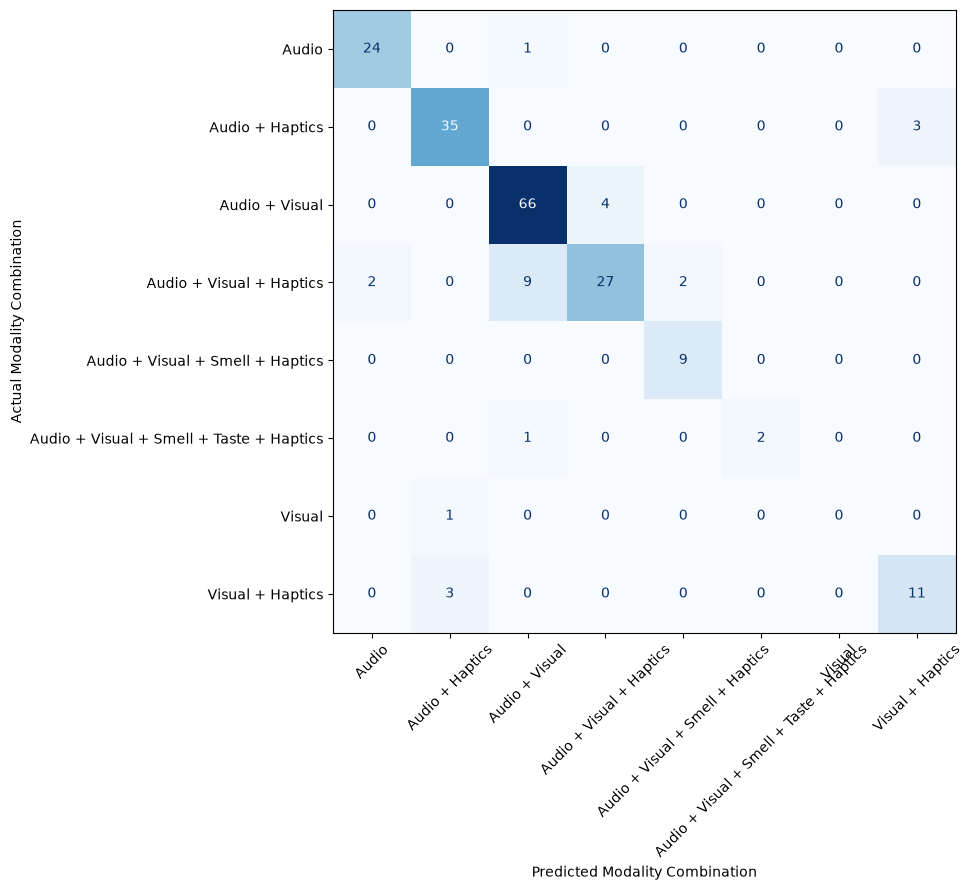



CONFUSION MATRIX COMPLETE
Controlled dataset size: 1000 calls
Training calls: 800
Testing calls: 200
Correct predictions: 174
Incorrect predictions: 26

Confusion matrix saved as:
Figure_4_5_Random_Forest_Confusion_Matrix_1000_Calls.png


------------------------------------------------------------------------------------------
ACTUAL VS PREDICTED RANDOM FOREST RESULTS
------------------------------------------------------------------------------------------


,Actual,Predicted,Correct
0,Audio,Audio,True
1,Visual,Audio + Haptics,False
2,Audio + Haptics,Audio + Haptics,True
3,Audio + Haptics,Audio + Haptics,True
4,Audio + Visual + Haptics,Audio + Visual + Haptics,True
...,...,...,...
195,Audio + Visual,Audio + Visual,True
196,Audio + Visual,Audio + Visual,True
197,Audio + Haptics,Audio + Haptics,True
198,Audio + Haptics,Audio + Haptics,True


In [75]:
# ============================================================
# FIGURE 4.5: FINAL RANDOM FOREST CONFUSION MATRIX
# DATASET-SIZE AGNOSTIC
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)


# ============================================================
# 1. VERIFY REQUIRED VARIABLES
# ============================================================

required_variables = [
    "train_data",
    "test_data",
    "model",
    "encoder",
    "CONTEXT_FEATURES"
]


missing_variables = [
    variable

    for variable in required_variables

    if variable not in globals()
]


if missing_variables:

    raise RuntimeError(
        "The following variables are missing: "
        + ", ".join(missing_variables)
        + "\nRun the shared split and final Random Forest "
          "training sections before generating this figure."
    )


if "Modalities" not in test_data.columns:

    raise ValueError(
        "The held-out test data does not contain "
        "the required 'Modalities' column."
    )


# ============================================================
# 2. DETERMINE CONTROLLED DATASET AND TEST SIZES
# ============================================================

controlled_total_calls = (
    len(train_data)
    +
    len(test_data)
)


expected_test_size = len(
    test_data
)


print("=" * 90)
print("FINAL RANDOM FOREST CONFUSION MATRIX")
print("=" * 90)


print(
    f"Controlled historical dataset: "
    f"{controlled_total_calls} calls"
)


print(
    f"Training calls: "
    f"{len(train_data)}"
)


print(
    f"Expected held-out predictions: "
    f"{expected_test_size}"
)


# Verify the strict 80/20 split.

if len(train_data) != int(controlled_total_calls * 0.80):

    raise ValueError(
        "The training set does not contain exactly 80% "
        "of the controlled dataset."
    )


if len(test_data) != int(controlled_total_calls * 0.20):

    raise ValueError(
        "The test set does not contain exactly 20% "
        "of the controlled dataset."
    )


# ============================================================
# 3. GENERATE RANDOM FOREST PREDICTIONS
# ============================================================

X_test_rf = encoder.transform(
    test_data[CONTEXT_FEATURES]
)


y_true = (
    test_data["Modalities"]
    .reset_index(drop=True)
)


y_pred = pd.Series(
    model.predict(X_test_rf)
)


if len(y_pred) != expected_test_size:

    raise ValueError(
        "The number of Random Forest predictions does not "
        "match the held-out test size."
    )


print(
    f"\nActual held-out predictions generated: "
    f"{len(y_pred)}"
)


# ============================================================
# 4. CREATE ACTUAL-VS-PREDICTED RESULTS TABLE
# ============================================================

rf_prediction_results = pd.DataFrame({

    "Actual": y_true,

    "Predicted": y_pred

})


rf_prediction_results["Correct"] = (

    rf_prediction_results["Actual"]

    ==

    rf_prediction_results["Predicted"]

)


print(
    "\nRandom Forest prediction results prepared."
)


print(
    f"Correct predictions: "
    f"{rf_prediction_results['Correct'].sum()}"
)


print(
    f"Incorrect predictions: "
    f"{(~rf_prediction_results['Correct']).sum()}"
)


# ============================================================
# 5. DETERMINE CLASSES FOR THE CONFUSION MATRIX
# ============================================================

labels = sorted(

    set(y_true)

    |

    set(y_pred)

)


print(
    f"\nModality classes represented in the matrix: "
    f"{len(labels)}"
)


# ============================================================
# 6. CALCULATE CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(

    y_true,

    y_pred,

    labels=labels

)


# ============================================================
# 7. PLOT CONFUSION MATRIX
# ============================================================

fig, ax = plt.subplots(

    figsize=(12, 9)

)


disp = ConfusionMatrixDisplay(

    confusion_matrix=cm,

    display_labels=labels

)


disp.plot(

    ax=ax,

    cmap="Blues",

    values_format="d",

    xticks_rotation=45,

    colorbar=False

)


ax.set_xlabel(
    "Predicted Modality Combination"
)


ax.set_ylabel(
    "Actual Modality Combination"
)


plt.tight_layout()


# ============================================================
# 8. SAVE FIGURE
# ============================================================

output_filename = (

    f"Figure_4_5_Random_Forest_Confusion_Matrix_"

    f"{controlled_total_calls}_Calls.png"

)


plt.savefig(

    output_filename,

    dpi=300,

    bbox_inches="tight"

)


plt.show()


# ============================================================
# 9. REPORT RESULTS
# ============================================================

print("\n")
print("=" * 90)
print("CONFUSION MATRIX COMPLETE")
print("=" * 90)


print(
    f"Controlled dataset size: "
    f"{controlled_total_calls} calls"
)


print(
    f"Training calls: "
    f"{len(train_data)}"
)


print(
    f"Testing calls: "
    f"{expected_test_size}"
)


print(
    f"Correct predictions: "
    f"{rf_prediction_results['Correct'].sum()}"
)


print(
    f"Incorrect predictions: "
    f"{(~rf_prediction_results['Correct']).sum()}"
)


print(
    "\nConfusion matrix saved as:"
)


print(
    output_filename
)


# ============================================================
# 10. DISPLAY THE UNDERLYING PREDICTION TABLE
# ============================================================

print("\n")
print("-" * 90)
print("ACTUAL VS PREDICTED RANDOM FOREST RESULTS")
print("-" * 90)


display(
    rf_prediction_results
)